# Bassez et al. 2021 — Breast Cancer
## 02 · Manifold — scFates curve, root, pseudotime

The scoped epithelial manifold is a single continuous low-cycling body (01). Here we determine **topology from the embedding** (curve vs tree), confirm there is **no Gast+pSom co-expression hub diverging into two arms** (so this is the non-branching case), fit a **curve**, root at the pSom-high / Crest-low developmental origin (Crest terminal; Gast weak/flat), and compute pseudotime. Continuity is judged off the fitted graph (fold self-approach ratio) and by **rendering the actual curve edges** on the manifold — not off a re-embedding, and not off a metric built from the same UMAP's neighbours.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold; module scores + geography
Re-derive smoothed module scores; raw means are the honest readout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('epithelial manifold:', adata.shape[0], 'cells,', adata.obs['sample'].nunique(), 'samples')
xy = adata.obsm['X_umap']; ctr = xy - xy.mean(0)
_,s,_ = np.linalg.svd(ctr, full_matrices=False)
print('UMAP principal-axis ratio (major/minor singular value): %.2f' % (s[0]/s[1]))
print('whole-manifold correlations (smoothed):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print('  %s vs %s: r = %+.2f' % (a,b, np.corrcoef(adata.obs[a],adata.obs[b])[0,1]))
print('raw:', {f'{a}/{b}': round(np.corrcoef(adata.obs[a],adata.obs[b])[0,1],2)
               for a,b in [('Gast','pSom'),('Crest','Gast'),('Crest','pSom')]})

epithelial manifold: 13834 cells, 34 samples
UMAP principal-axis ratio (major/minor singular value): 1.46
whole-manifold correlations (smoothed):
  Gast_sm vs pSom_sm: r = -0.70
  Crest_sm vs Gast_sm: r = +0.55
  Crest_sm vs pSom_sm: r = -0.91
raw: {'Gast/pSom': np.float64(-0.15), 'Crest/Gast': np.float64(-0.34), 'Crest/pSom': np.float64(-0.61)}


### Hub test — is there a Gast+pSom co-expression hub? (branching prerequisite)
A branching manifold requires a population where **Gast and pSom are co-expressed** (the hub) that then diverges into a Gast-leaning and a pSom-leaning arm. We test co-expression enrichment: fraction of cells high in *both* modules vs the independent expectation. Enrichment < 1 means the modules are **mutually exclusive** (cross-repression), not a co-expression hub → non-branching.

In [4]:
z = lambda x: (x-np.mean(x))/np.std(x)
gz, pz = z(adata.obs['Gast_sm'].values), z(adata.obs['pSom_sm'].values)
both = ((gz>0.5)&(pz>0.5)).mean(); exp = (gz>0.5).mean()*(pz>0.5).mean()
print('Gast&pSom both-high fraction = %.3f vs independent expectation %.3f -> enrichment %.2f' % (both, exp, both/exp))
print('  (>1 = co-expression hub [branching]; <1 = mutual exclusivity / cross-repression [non-branching])')
print('-> no co-expression hub: the Gast/pSom axis is cross-repressive, not a diverging hub')

Gast&pSom both-high fraction = 0.012 vs independent expectation 0.108 -> enrichment 0.11
  (>1 = co-expression hub [branching]; <1 = mutual exclusivity / cross-repression [non-branching])
-> no co-expression hub: the Gast/pSom axis is cross-repressive, not a diverging hub


### Topology check — curve vs tree, read off the embedding
Fit scFates `curve` over a node sweep and a PPT `tree`. The fold self-approach ratio (min graph-distant node distance / median edge) > 1 = fold-free. Crucially we then **render every tree tip's biology**: a genuine bifurcation needs a Gast-high tip *and* a pSom-high tip. If all tips are pSom-high / Gast-low, the tree's forks are lobe over-fitting, not a Gast/pSom bifurcation → curve.

In [5]:
def fold_diag(a):
    B = np.asarray(a.uns['graph']['B']); F = a.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for x in range(F.shape[0]):
        for y in range(x+1, F.shape[0]):
            if G[x,y] >= 3: dmin = min(dmin, np.sqrt(((F[x]-F[y])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
for Nn in [15, 20, 30]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks = fold_diag(a2); print('curve N=%d: %d tips, %d forks | self-approach %.2f' % (Nn,tips,forks,sa))
# PPT tree tips biology
at = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(at, Nodes=20, use_rep='X_umap', method='ppt', ppt_lambda=2000, ppt_sigma=0.5, seed=SEED, plot=False)
Bt = np.asarray(at.uns['graph']['B']); Rt = np.asarray(at.obsm['X_R']); hard = Rt.argmax(1)
Dt = shortest_path(sp.csr_matrix((Bt>0).astype(int)), unweighted=True)
tps = np.where((Bt>0).sum(0)==1)[0]
print('PPT tree N=20: %d tips, %d forks -- tip biology:' % (len(tps), int(((Bt>0).sum(0)>=3).sum())))
for tp in tps:
    m = np.isin(hard, np.where(Dt[tp]<=3)[0])
    print('  tip %2d (n=%d): Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (tp, m.sum(),
          adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean()))
print('-> all tips pSom-high / Gast-low: no Gast arm -> forks are pSom-lobe over-fit, not a bifurcation')

curve N=15: 2 tips, 0 forks | self-approach 2.99
curve N=20: 2 tips, 0 forks | self-approach 2.99
curve N=30: 2 tips, 0 forks | self-approach 2.94
PPT tree N=20: 4 tips, 2 forks -- tip biology:
  tip  5 (n=3251): Gast=-0.0288 pSom=+0.0349 Crest=-0.0137
  tip  8 (n=3524): Gast=-0.0323 pSom=+0.0423 Crest=-0.0161
  tip  9 (n=4209): Gast=-0.0245 pSom=+0.0212 Crest=-0.0049
  tip 10 (n=2446): Gast=-0.0208 pSom=+0.0163 Crest=-0.0043
-> all tips pSom-high / Gast-low: no Gast arm -> forks are pSom-lobe over-fit, not a bifurcation


### Fit the curve (non-branching)

In [6]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks = fold_diag(adata)
print('chosen curve N=20: %d tips, %d forks | fold self-approach ratio = %.2f (>1 = fold-free)' % (tips,forks,sa))
assert forks == 0 and sa > 1, 'topology check failed'

chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.99 (>1 = fold-free)


### Root from developmental order
Crest is the developmentally LATE / terminal program (and here rises strongly with the resolved axis); the origin is the **Crest-low** end. Compare the two curve tips and root at the Crest-low tip — which is also the **pSom-high** end. Note Gast is weak/flat on this compartment (near-zero, small dynamic range) and trends weakly toward the terminus with Crest, while pSom falls from the root: the resolved developmental axis is **somitogenesis (pSom, early) → neural crest (Crest, late)**, with Gast/pSom cross-repressing. Verify gradients and that the axis is not proliferation-driven.

In [7]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % ((tp,)+info[tp]))
# origin = Crest-low (developmentally early) tip; confirmed pSom-high there
root = int(min(tps, key=lambda tp: info[tp][2]))
print('derived root = tip', root, '(Crest-low, pSom-high developmental origin; Gast weak/flat)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for smod in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[smod]); print('  %s: rho=%+.3f p=%.1e' % (smod,rho,p))
print('  -> pSom falls (early/root); Crest rises (late/terminus); Gast weak and trends with the terminus')
for m,lab in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print('%s-high decile mean pseudotime = %.2f' % (lab, tn[hi.values].mean()))
g2m = pd.to_numeric(adata.obs.get('g2m_score', pd.Series(0,index=adata.obs_names)), errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs.get('g1s_score', pd.Series(0,index=adata.obs_names)), errors='coerce').fillna(0).values
rho_c,_ = spearmanr(t, np.maximum(g1s,g2m))
print('caveat: pseudotime vs cycling score rho = %+.2f (secondary; axis not proliferation-driven)' % rho_c)

tip 0: Gast=-0.0281 pSom=+0.0334 Crest=-0.0127
tip 2: Gast=-0.0258 pSom=+0.0227 Crest=-0.0057
derived root = tip 0 (Crest-low, pSom-high developmental origin; Gast weak/flat)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.161 p=1.1e-80
  pSom_sm: rho=-0.339 p=0.0e+00
  Crest_sm: rho=+0.443 p=0.0e+00
  -> pSom falls (early/root); Crest rises (late/terminus); Gast weak and trends with the terminus
Neural-crest-high decile mean pseudotime = 0.82
Somitogenesis-high decile mean pseudotime = 0.43
Gastrulation-high decile mean pseudotime = 0.75
caveat: pseudotime vs cycling score rho = -0.11 (secondary; axis not proliferation-driven)


### House orientation consistent with pseudotime

In [8]:
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
print('corr(x_lin, pseudotime) = %+.2f (origin on left, terminus on right)' % r)

corr(x_lin, pseudotime) = +0.99 (origin on left, terminus on right)


### Render the fitted curve edges on the manifold — in-notebook fold check
The committed curve is drawn as edges over the cloud **inline in this notebook** (not saved as a separate figure — the §6 figure set is kept to `manifold.pdf`): a reviewer can *see* it is a single fold-free backbone (no U/W self-approach), rather than judging continuity from a neighbour metric.

rendered curve edges inline; fold-free (self-approach>1) = True


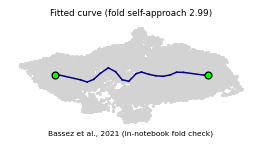

In [9]:
Bc = np.asarray(adata.uns['graph']['B']); Fc = adata.uns['graph']['F'].T
# express node positions in house orientation for the render
# (curve was fit on X_umap; map nodes via nearest cells' mean offset is unnecessary -- re-fit coords via same rotation)
fig, ax = plt.subplots(figsize=(3.5,1.5))
xl = adata.obsm['X_umap_lin']
ax.scatter(xl[:,0], xl[:,1], c='lightgray', s=6, linewidth=0)
# node coords in umap_lin: nearest-cell assignment average
Rr = np.asarray(adata.obsm['X_R']); node_xy = (Rr.T @ xl) / Rr.sum(0)[:,None]
ii,jj = np.where(np.triu(Bc>0))
for x,y in zip(ii,jj):
    ax.plot([node_xy[x,0],node_xy[y,0]],[node_xy[x,1],node_xy[y,1]], '-', color='navy', lw=1.2, zorder=5)
deg = (Bc>0).sum(0); tipn = np.where(deg==1)[0]
ax.scatter(node_xy[tipn,0], node_xy[tipn,1], c='lime', s=30, edgecolor='k', zorder=6)
ax.set_title('Fitted curve (fold self-approach %.2f)' % sa, size=7); ax.axis('off')
ax.text(.5,-.08,'Bassez et al., 2021 (in-notebook fold check)', ha='center', transform=ax.transAxes, size=6)
plt.show()   # inline fold check only -- NOT saved to figures dir (keeps the §6 set tidy)
print('rendered curve edges inline; fold-free (self-approach>1) =', sa>1)

### Save manifold.h5ad + manifold.pdf (pseudotime)

saved manifold.h5ad + manifold.pdf


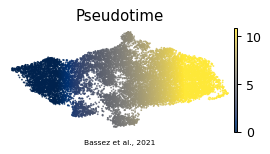

In [10]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=8, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')